# ES for ht for classification 

## The NN

In [1]:
import time 
import pandas
import random
import json, argparse

# ML
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from plotly import graph_objects as go
from sklearn import preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, roc_auc_score

# pytorch
import torch.nn as nn
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import torch.utils

# software modules
import models_regression as Models
import utils
import dataset as Dataset


In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print('Using device:', device)

Using device: cpu


In [3]:
num_samples = 2000 # put 50000

dataset = pd.read_parquet('./data/WRT1V.parquet')
dataset = dataset.drop(['Label_10', 'Label_20', 'Label_30', 'Label_50', 'Label_100', 'Day'], axis=1)
dataset['mid_price'] = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2
dataset = dataset.astype(float)
dataset = dataset.head(num_samples)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price
0,0.962048,0.008123,0.964492,0.006633,0.962048,0.013564,0.964492,0.006650,0.961623,0.011154,...,0.019060,0.956217,0.004534,0.964476,0.004935,0.955381,0.002298,0.964048,0.025081,0.963270
1,0.961606,0.004041,0.964492,0.002583,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
2,0.961606,0.004041,0.964492,0.005917,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
3,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
4,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,0.956311,0.005756,0.959166,0.004733,0.956311,0.152281,0.959166,0.005683,0.956330,0.024448,...,0.012136,0.950525,0.004363,0.959591,0.009996,0.950569,0.040200,0.959609,0.024804,0.957738
1996,0.956311,0.005756,0.959166,0.004733,0.956311,0.152281,0.959166,0.005683,0.956330,0.024448,...,0.012136,0.950525,0.004363,0.959591,0.009996,0.950569,0.040200,0.959609,0.024804,0.957738
1997,0.956311,0.005756,0.959166,0.004733,0.956311,0.152281,0.959166,0.005683,0.956330,0.024448,...,0.012136,0.950525,0.004363,0.959591,0.009996,0.950569,0.040200,0.959609,0.024804,0.957738
1998,0.956311,0.005756,0.959166,0.004733,0.956311,0.152281,0.959166,0.005683,0.956330,0.024448,...,0.012136,0.950525,0.004363,0.959591,0.009996,0.950569,0.040200,0.959609,0.024804,0.957738


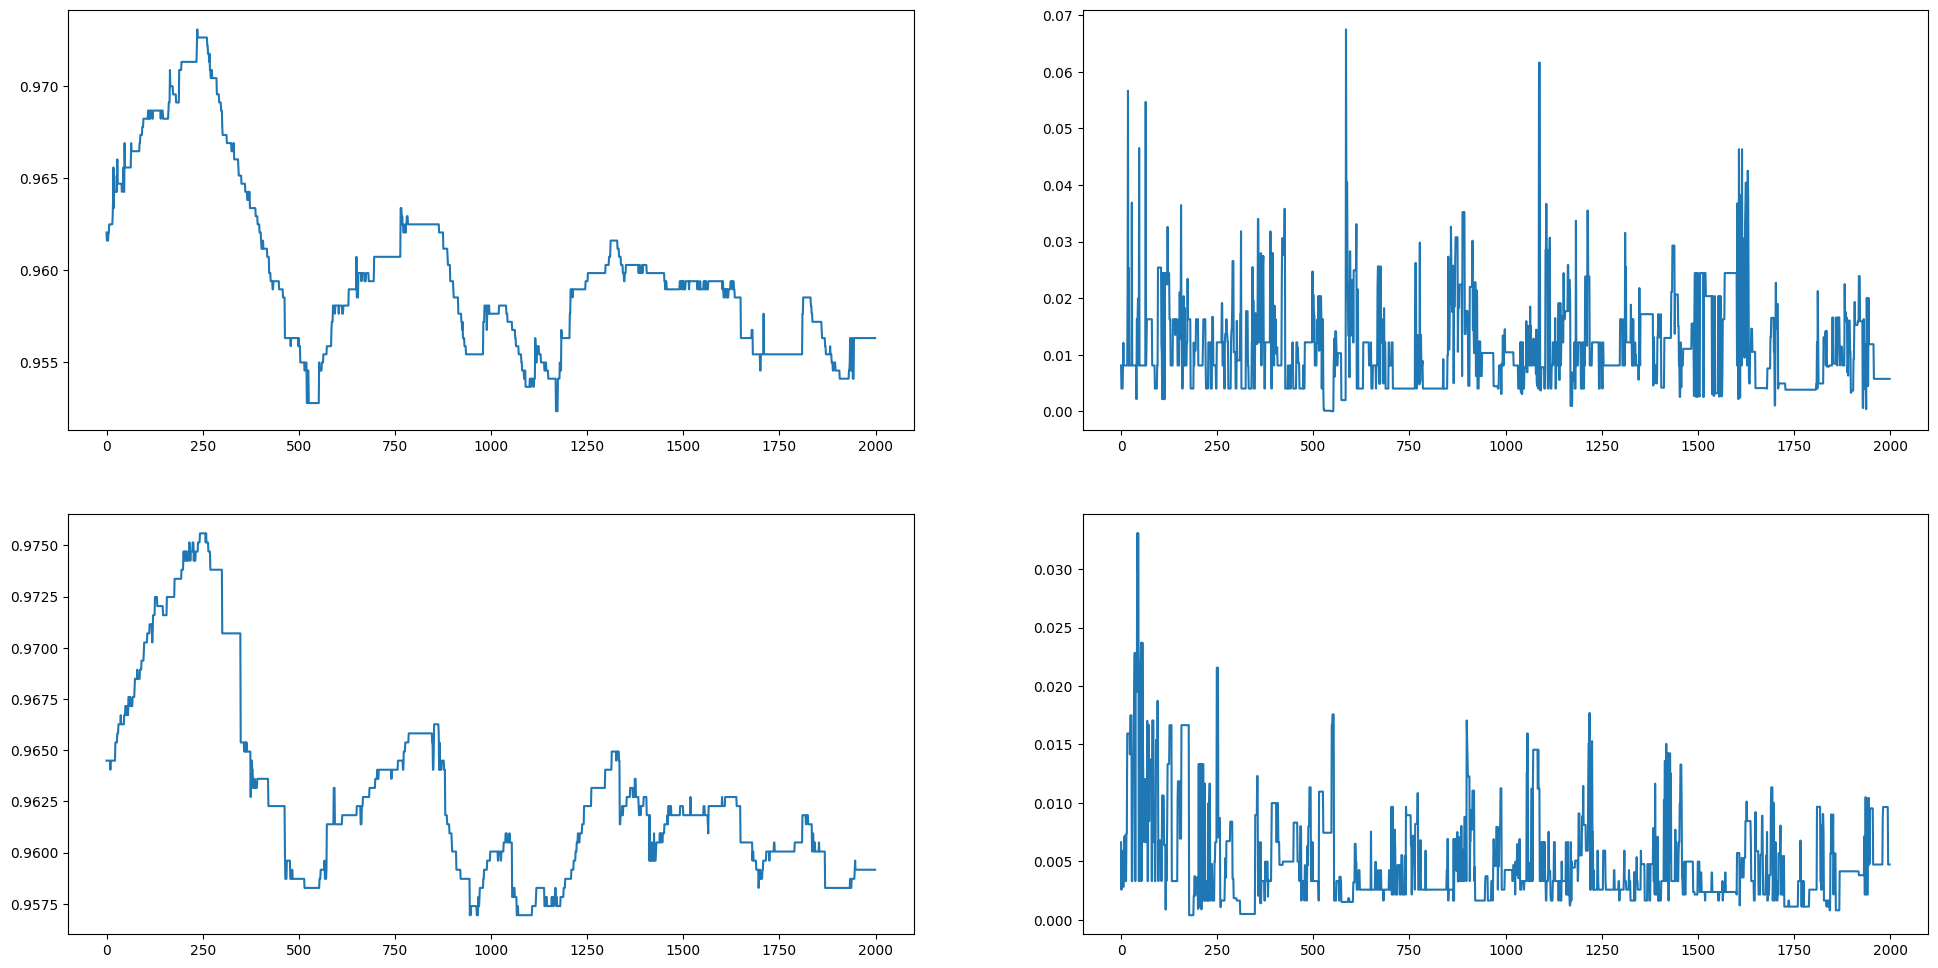

In [4]:
_, axs = plt.subplots(2, 2, figsize=(24,12))
axs[0,0].plot(dataset['P_Ask_1'])
axs[0,1].plot(dataset['V_Ask_1'])
axs[1,0].plot(dataset['P_Bid_1'])
axs[1,1].plot(dataset['V_Bid_1'])
plt.show()

In [5]:
target_col = 'mid_price'
target_cols = []
shifts = [ 1, 10, 20, 50 ]

for shift in shifts:
    colname = f'Target_{shift}'
    target_cols.append(colname)
    dataset[colname] = dataset[target_col].shift(-shift)
dataset.dropna(inplace=True)

display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price,Target_1,Target_10,Target_20,Target_50
0,0.962048,0.008123,0.964492,0.006633,0.962048,0.013564,0.964492,0.006650,0.961623,0.011154,...,0.004935,0.955381,0.002298,0.964048,0.025081,0.963270,0.963049,0.963268,0.964814,0.966367
1,0.961606,0.004041,0.964492,0.002583,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049,0.963049,0.963490,0.964373,0.966367
2,0.961606,0.004041,0.964492,0.005917,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049,0.963049,0.963490,0.964373,0.966145
3,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049,0.963049,0.963490,0.964817,0.966367
4,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049,0.963270,0.963490,0.964817,0.966367
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1945,0.956311,0.011879,0.958722,0.010417,0.956311,0.152281,0.958722,0.010483,0.956330,0.024448,...,0.024952,0.950569,0.040200,0.959166,0.009468,0.957516,0.957738,0.957738,0.957738,0.957738
1946,0.956311,0.011879,0.959166,0.004733,0.956311,0.152281,0.959166,0.012083,0.956330,0.024448,...,0.022585,0.950569,0.040200,0.959609,0.024804,0.957738,0.957960,0.957738,0.957738,0.957738
1947,0.956311,0.011879,0.959609,0.004983,0.956311,0.152281,0.959609,0.004733,0.956330,0.024448,...,0.012136,0.950569,0.040200,0.960053,0.022437,0.957960,0.957738,0.957738,0.957738,0.957738
1948,0.956311,0.011879,0.959166,0.009533,0.956311,0.152281,0.959166,0.008233,0.956330,0.024448,...,0.024952,0.950569,0.040200,0.959166,0.009468,0.957738,0.957738,0.957738,0.957738,0.957738


In [6]:
# Split the dataframe into train, validation and test
dataset_train, dataset_val, dataset_test = utils.DataTools.train_val_test_split(dataset)

# Standardize the data
#scaler = preprocessing.StandardScaler()
#scaler.fit(dataset_train)

#dataset_train[dataset_train.columns] = scaler.transform(dataset_train)
#dataset_val[dataset_val.columns] = scaler.transform(dataset_val)
#dataset_test[dataset_test.columns] = scaler.transform(dataset_test)

means = dataset_train.mean(axis=0)
stds = dataset_train.std(axis=0)

means[-len(target_cols):] = means[target_cols]
stds[-len(target_cols):] = stds[target_cols]

dataset_train = ( dataset_train - means ) / stds
dataset_val = ( dataset_val - means ) / stds
dataset_test = ( dataset_test - means ) / stds

display(dataset_train)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price,Target_1,Target_10,Target_20,Target_50
0,0.196973,-0.383998,0.126882,0.257553,0.142177,-0.503591,0.187442,0.129192,0.095667,-0.633776,...,-0.731524,-0.071737,-0.706651,0.246252,0.907762,0.162776,0.119700,0.164850,0.471448,0.797276
1,0.110603,-0.889351,0.126882,-0.613008,0.055343,-0.503591,0.187442,-0.609185,0.008552,-0.633776,...,0.281622,-0.302502,1.544828,0.408360,-0.673805,0.119478,0.119700,0.208398,0.384836,0.797276
2,0.110603,-0.889351,0.126882,0.103503,0.055343,-0.503591,0.187442,-0.609185,0.008552,-0.633776,...,0.281622,-0.302502,1.544828,0.408360,-0.673805,0.119478,0.119700,0.208398,0.384836,0.753583
3,0.110603,-0.889351,0.126882,-0.498366,0.055343,-0.503591,0.187442,0.129192,0.008552,-0.633776,...,0.281622,-0.302502,1.544828,0.408360,-0.673805,0.119478,0.119700,0.208398,0.471947,0.797276
4,0.110603,-0.889351,0.126882,-0.498366,0.055343,-0.503591,0.187442,0.129192,0.008552,-0.633776,...,0.281622,-0.302502,1.544828,0.408360,-0.673805,0.119478,0.162999,0.208398,0.471947,0.797276
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1360,-0.148504,0.737886,-0.218297,-0.143693,-0.031489,-0.739613,-0.160782,-0.033251,0.008552,0.799095,...,1.357977,0.466712,-0.535579,-0.077966,-0.353960,-0.184610,-0.184388,-0.182289,-0.179141,-0.291808
1361,-0.148504,0.737886,-0.218297,-0.143693,-0.031489,-0.739613,-0.160782,-0.033251,0.008552,0.799095,...,1.357977,0.466712,-0.535579,-0.077966,-0.353960,-0.184610,-0.140840,-0.182289,-0.179141,-0.291808
1362,-0.148504,0.737886,-0.132003,-0.813631,-0.031489,-0.739613,-0.073727,-0.287991,0.008552,0.799095,...,-0.912121,0.466712,-0.535579,0.246252,3.468489,-0.141062,-0.140840,-0.182289,-0.179141,-0.510277
1363,-0.148504,0.737886,-0.132003,-0.813631,-0.031489,-0.739613,-0.073727,-0.287991,0.008552,0.799095,...,-0.912121,0.466712,-0.535579,0.246252,3.468489,-0.141062,-0.140840,-0.182289,-0.179141,-0.291808


In [7]:
# Split covariates and response variables
X_train, y_train = utils.DataTools.split_x_y(dataset_train, target_cols)
X_val, y_val = utils.DataTools.split_x_y(dataset_val, target_cols)
X_test, y_test = utils.DataTools.split_x_y(dataset_test, target_cols)

# Convert to pytorch tensors
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, dtype=torch.float32 )

# Create Torch Dataset
lookback_period = 100
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = True,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = True,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = True,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)

# Create Torch DataLoader
batch_size = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = batch_size,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = batch_size,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 1024,
    shuffle = False
)

print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 1166 samples
Test dataset: 94 samples


## The Sam Evolutionary Strategy Tuning 

In [8]:
# Import tuning module
import es_tuning_LobCNN_functions as esr

In [9]:
# Example usage
max_fitness_evaluations = 10        # change it to 100
num_epochs_per_nn_evaluation = 1    # change it to 30

mu_population_size = 2              # change it to 10
lambda_offsprings_size = 3          # change it to 20

init_unitsNumber_interval = [32,128]

nn_training_data = dataloader_train
nn_validation_data = dataloader_test
nn_input_size = X_train.shape[1]
nn_output_size = y_train.shape[1]
device = 'cpu' # 'cuda'

csv_file_path = './csv_results/es_LobCNN.csv'

init_layersNumber_interval = [1,1]  
init_activation_functions = [nn.ReLU] 
init_lr_interval = (5e-6, 5e-3)
init_dropout_interval = (0.0, 0.4)
maximize_fitness = False

tornamentPercentage_for_offspringGeneration = 0.2
p_crossover_vs_mutation = 0.75
structure_k_value_for_crossover = 0
structure_lb_size = 32
structure_ub_size = 150
lr_k = 0
dropout_k = 0
lr_lb = 5e-6
lr_ub = 5e-3
dropout_lb = 0.0
dropout_ub = 0.4


best_individual_ever = esr.es_lambdaMu_sld_regression(
    max_fitness_evaluations = max_fitness_evaluations,
    mu_population_size = mu_population_size,
    init_layersNumber_interval = init_layersNumber_interval,
    init_unitsNumber_interval = init_unitsNumber_interval,
    init_activation_functions = init_activation_functions,
    init_lr_interval = init_lr_interval,
    init_dropout_interval = init_dropout_interval,
    nn_training_data = nn_training_data,
    nn_validation_data = nn_validation_data,
    num_epochs_per_nn_evaluation = num_epochs_per_nn_evaluation,
    nn_input_size = nn_input_size,
    nn_output_size = nn_output_size,
    device = device,
    maximize_fitness = maximize_fitness,
    lambda_offsprings_size = lambda_offsprings_size,
    tornamentPercentage_for_offspringGeneration = tornamentPercentage_for_offspringGeneration,
    p_crossover_vs_mutation = p_crossover_vs_mutation,
    structure_k_value_for_crossover = structure_k_value_for_crossover,
    structure_lb_size = structure_lb_size,
    structure_ub_size = structure_ub_size,
    lr_k = lr_k,
    dropout_k = dropout_k,
    lr_lb = lr_lb,
    lr_ub = lr_ub,
    dropout_lb = dropout_lb,
    dropout_ub = dropout_ub,
    csv_file_path=csv_file_path)

Training:   0%|          | 0/1 [00:00<?, ?it/s]

/home/samuele/.local/lib/python3.10/site-packages/torch/nn/modules/conv.py:456: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at ../aten/src/ATen/native/Convolution.cpp:1031.)
  return F.conv2d(input, weight, bias, self.stride,


Training:   0%|          | 0/1 [00:00<?, ?it/s]

Estimated time: 0 hours and 0 minutes
Generation 1: 2 fitness evaluations, best individual: Individual: nn_gene = [51], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.0036957349875649695, dropout = 0.288119672882946 | nn_sol = [51], Fitness = 0.06805643439292908


Training:   0%|          | 0/1 [00:00<?, ?it/s]

Training:   0%|          | 0/1 [00:00<?, ?it/s]

... (6 outputs left out)

Training:   0%|          | 0/1 [00:00<?, ?it/s]

Training:   0%|          | 0/1 [00:00<?, ?it/s]

Training:   0%|          | 0/1 [00:00<?, ?it/s]

Generation 4: 11 fitness evaluations, best individual: Individual: nn_gene = [69.64422109131714], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.0035849568560623025, dropout = 0.3514061562203651 | nn_sol = [70], Fitness = 0.04713161289691925
Best individual ever: Individual: nn_gene = [69.64422109131714], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.0035849568560623025, dropout = 0.3514061562203651 | nn_sol = [70], Fitness = 0.04713161289691925


# Test the tuned model

In [10]:
import sam_plots

In [11]:
# Create model with standard parameters
params = {
    "vertical_convolutional_layers" : 2,
    "vertical_kernel_size" : 4,
    "smoothing" : False,
    "convolution_channels" : 32,
    "inception_channels" : 64,
    "lstm_layers" : 2,
    "latent_size" : 128,
    "dropout" : 0.2,
    "output_size" : y_train.shape[1],
}

model = Models.LobCNN(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = model.name,
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = False,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

In [12]:
# Create model with tuned parameters
params = {
    "vertical_convolutional_layers" : 2,
    "vertical_kernel_size" : 4,
    "smoothing" : False,
    "convolution_channels" : 32,
    "inception_channels" : 64,
    "lstm_layers" : 2,
    "latent_size" : best_individual_ever.structure_solution[0],
    "dropout" : best_individual_ever.dropout_solution,
    "output_size" : y_train.shape[1],
}

model = Models.LobCNN(**params).to(device)

# Define loss function and optimizer
learning_rate = best_individual_ever.lr_solution
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
tuned_training_info = utils.ModelTools.train(
    model_id = model.name,
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = False,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

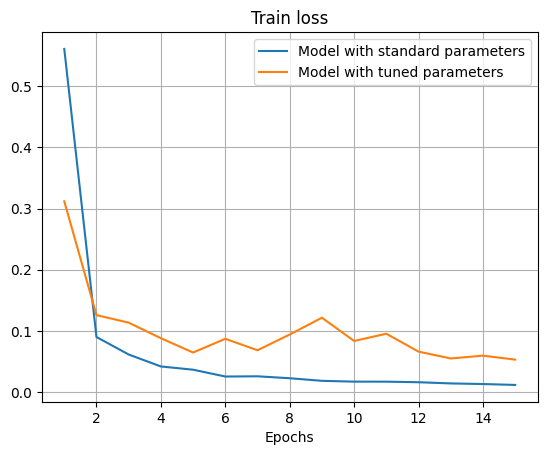

In [13]:
sam_plots.plot_2_histories(
    training_info['train_loss'],
    tuned_training_info['train_loss'],
    "Train loss",
    "Model with standard parameters",
    "Model with tuned parameters"
    )

##